In [59]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns

from pathlib import Path

# loading weather dataset 

data = Path("../../data/raw/tetovo_weather_era5_2017_2026_utc.csv")

df= pd.read_csv(data)


In [60]:
# Dataset overview

print("Dataset shape:", df.shape)

display(df.head())
df.info()

Dataset shape: (85440, 7)


,timestamp_utc,temperature_c,humidity_pct,wind_speed_kmh,wind_direction_deg,pressure_msl_hpa,precipitation_mm
0,2017-01-01 00:00:00+00:00,-10.8,88,5.8,274,1030.9,0.0
1,2017-01-01 01:00:00+00:00,-11.2,87,5.8,266,1030.2,0.0
2,2017-01-01 02:00:00+00:00,-12.4,89,5.4,262,1029.6,0.0
3,2017-01-01 03:00:00+00:00,-12.6,89,5.5,259,1028.6,0.0
4,2017-01-01 04:00:00+00:00,-12.8,88,5.4,262,1028.1,0.0


<class 'pandas.DataFrame'>
RangeIndex: 85440 entries, 0 to 85439
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   timestamp_utc       85440 non-null  str    
 1   temperature_c       85440 non-null  float64
 2   humidity_pct        85440 non-null  int64  
 3   wind_speed_kmh      85440 non-null  float64
 4   wind_direction_deg  85440 non-null  int64  
 5   pressure_msl_hpa    85440 non-null  float64
 6   precipitation_mm    85440 non-null  float64
dtypes: float64(4), int64(2), str(1)
memory usage: 4.6 MB


## 2. Data Quality Assessment

This section examines missing values, duplicate records,
timestamp consistency, and basic data validity in the
historical Tetovo weather dataset.

In [61]:
# Coverting timestamps datatype from string to UTC datetime

df['timestamp_utc'] = pd.to_datetime(
    df['timestamp_utc'], utc=True
)

print(df['timestamp_utc'])
print('\nStart:', df['timestamp_utc'].min())
print('\nEnd:', df['timestamp_utc'].max())


0       2017-01-01 00:00:00+00:00
1       2017-01-01 01:00:00+00:00
2       2017-01-01 02:00:00+00:00
3       2017-01-01 03:00:00+00:00
4       2017-01-01 04:00:00+00:00
                   ...           
85435   2026-09-30 19:00:00+00:00
85436   2026-09-30 20:00:00+00:00
85437   2026-09-30 21:00:00+00:00
85438   2026-09-30 22:00:00+00:00
85439   2026-09-30 23:00:00+00:00
Name: timestamp_utc, Length: 85440, dtype: datetime64[us, UTC]

Start: 2017-01-01 00:00:00+00:00

End: 2026-09-30 23:00:00+00:00


### Checking Missing values and dublicated

In [62]:
# Checking for missing values in the dataset 

print("Missing values:")
print(df.isna().sum())

Missing values:
timestamp_utc         0
temperature_c         0
humidity_pct          0
wind_speed_kmh        0
wind_direction_deg    0
pressure_msl_hpa      0
precipitation_mm      0
dtype: int64


In [63]:
# Checking for Duplicate rows 
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [64]:
# Duplicate timestamps

print(
    "Duplicate timestamps:",
    df['timestamp_utc'].duplicated().sum()
)

Duplicate timestamps: 0


###  Check timestamp continuity

In [65]:
#Sorting data accourding to timestamp in acending order 

df = df.sort_values("timestamp_utc").reset_index(drop = True)

# Calculate intervals between records

intervals = df['timestamp_utc'].diff().dropna()

print("Timestamp interval frequencies:")
print(intervals.value_counts())

Timestamp interval frequencies:
timestamp_utc
0 days 01:00:00    85439
Name: count, dtype: int64


In [66]:
#checking for gaps

expected_hours = pd.date_range(
    start= df['timestamp_utc'].min(),
    end= df['timestamp_utc'].max(),
    freq="h", 
    tz= 'UTC'
)

missing_hours = expected_hours.difference(df['timestamp_utc'])
print("Missing hourly timestamps:",len(missing_hours))

Missing hourly timestamps: 0


## 3.Descriptive Statistical Analysis

This section summarizes the statistical properties of historical weather conditions in Tetovo from 2017 to 2026.

We examine measures of central tendency, variability,and extreme values to better understand the dataset.

In [67]:
# Select weather variables 

weather_cols = [
    "temperature_c",
    "humidity_pct",
    "wind_speed_kmh",
    "wind_direction_deg",
    "pressure_msl_hpa",
    "precipitation_mm",
]

# Descriptive statistics 

stats= df[weather_cols].describe()

#Add missing value counts 


print(stats.round(2))

       temperature_c  humidity_pct  wind_speed_kmh  wind_direction_deg  \
count       85440.00      85440.00        85440.00            85440.00   
mean           13.81         73.38            4.92              206.45   
std             9.14         19.35            2.18              107.30   
min           -22.80         17.00            0.00                1.00   
25%             6.90         59.00            3.40              129.00   
50%            13.50         78.00            4.70              239.00   
75%            20.30         90.00            6.20              283.00   
max            39.20        100.00           18.20              360.00   

       pressure_msl_hpa  precipitation_mm  
count          85440.00          85440.00  
mean            1017.45              0.12  
std                6.69              0.38  
min              988.70              0.00  
25%             1013.40              0.00  
50%             1017.10              0.00  
75%             1021.20  

In [68]:
# Additional statistical measures

additional_stats = pd.DataFrame({

    'Skewness' : df[weather_cols].skew(),
    'Missing (%)' : df[weather_cols].isna().mean() * 100,

})

print(additional_stats.round(2))

                    Skewness  Missing (%)
temperature_c           0.04          0.0
humidity_pct           -0.60          0.0
wind_speed_kmh          0.69          0.0
wind_direction_deg     -0.55          0.0
pressure_msl_hpa        0.15          0.0
precipitation_mm        5.70          0.0


## 4. Univariate Analysis

### 4.1 Temperature Distribution

This visualization examines the frequency distribution of hourly temperature observations in Tetovo.

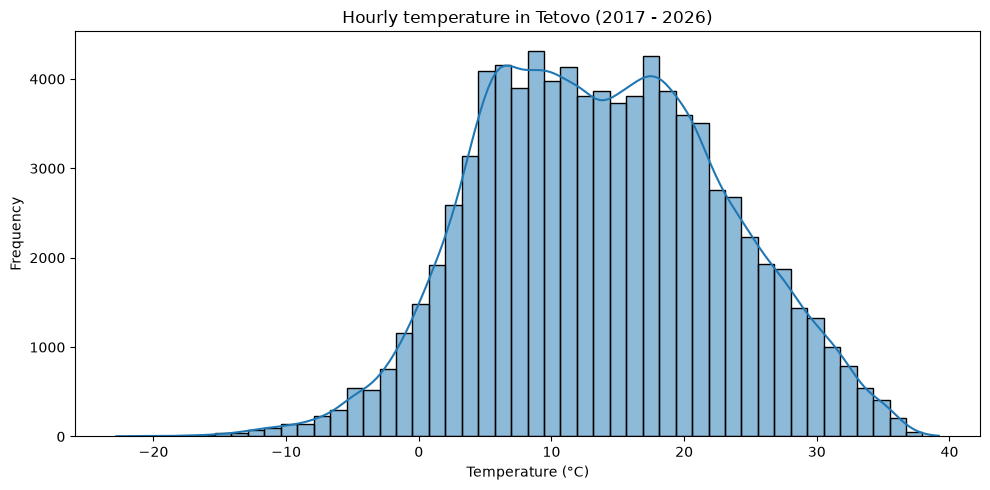

In [69]:
plt.figure(figsize=(10,5))

sns.histplot(
    data = df, 
    x= 'temperature_c',
    bins=50, 
    kde= True ,
)
plt.title("Hourly temperature in Tetovo (2017 - 2026)")
plt.xlabel("Temperature (°C)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

### Key Takeaways: Temperature Patterns

Looking at the hourly temperature data in Tetovo (from 2017 to September 2026), we can see that the weather changes a lot over the course of the year.

**Main Findings:**
* **Two Main Peaks:** The temperature hits two common sweet spots—one around **7–9°C** and another around **17–19°C**.
* **Most Common Range:** The vast majority of hourly readings land between **0°C and 25°C**.
* **Rare Extremes:** Extremely cold or unusually hot days don't happen nearly as often.
* **Not a Simple Bell Curve:** The distribution isn't a perfect, symmetric bell curve, which makes sense because seasonal shifts pull temperatures up and down throughout the year.

---

### Why This Matters for Air Pollution Prediction

Temperature is a huge factor when trying to predict air quality. Big changes in seasons and atmospheric conditions often line up with spikes or drops in pollution levels. 

Once we combine our weather and air pollution data, we'll check how strong these connections actually are with real numbers rather than just assuming temperature causes pollution directly.

In [70]:
# Calculate temperature  statistics 
temp = df['temperature_c']

print("Mean Temperature:", round(temp.mean(),2), "°C")
print("Median temperature:",round(temp.median(),2),"°C")
print("Minimum temperature", temp.min(),"°C")
print("Maximum temperature", temp.max(),"°C")
print("Standard deviation:", round(temp.std(),2,),"°C")

#Calculating percentage of hours  between 0°C and 25°C
percentage = temp.between(0,25).mean() *100
print(
    "Percentage of observations between 0°C and 25°C:", 
    round(percentage,2),"%"
)

Mean Temperature: 13.81 °C
Median temperature: 13.5 °C
Minimum temperature -22.8 °C
Maximum temperature 39.2 °C
Standard deviation: 9.14 °C
Percentage of observations between 0°C and 25°C: 82.44 %


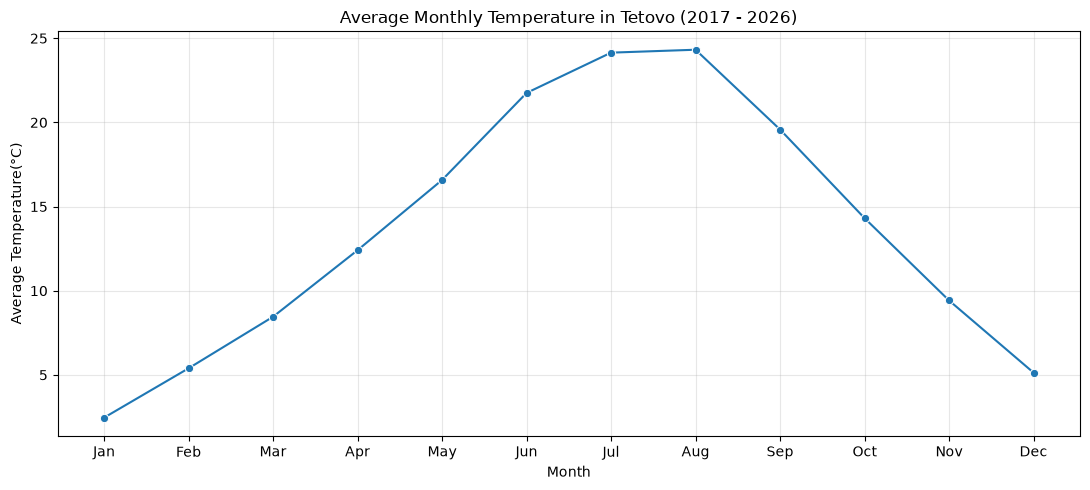

In [71]:
# converting timsestamps to Tetovo time 

df['timestamp_local'] = (
    df['timestamp_utc'].dt.tz_convert("Europe/Skopje")
)

# Extract month 

df['month'] = df["timestamp_local"].dt.month

# Average temperature by month 
monthly_temp = (
    df.groupby('month')['temperature_c'].mean()
)

plt.figure(figsize=(11,5))
sns.lineplot(
    x= monthly_temp.index, 
    y= monthly_temp.values, 
    marker='o'
)

plt.xticks(
    range(1,13),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)

plt.title("Average Monthly Temperature in Tetovo (2017 - 2026)")
plt.xlabel("Month")
plt.ylabel("Average Temperature(°C)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Key Observations — Monthly Temperature Patterns

Looking at the month-by-month averages from 2017 to 2026, Tetovo has a very clear and predictable seasonal cycle.

**Main Findings:**
* **Winter:** January is the coldest month of the year (averaging around 2.5°C), with December and February close behind.
* **Spring:** Temperatures steadily climb from March through May as the weather warms up.
* **Summer:** July and August are the hottest months, averaging about 24°C.
* **Autumn:** Things cool down step-by-step from September to November.
* **The Big Swing:** Overall, there is a massive **22°C difference** between the average temperature of the coldest month and the hottest month.

---

### Why This Matters for Air Pollution Prediction

Because the seasons change in such a steady, predictable pattern, tracking the month and the temperature will likely be super helpful when building our air pollution model. 


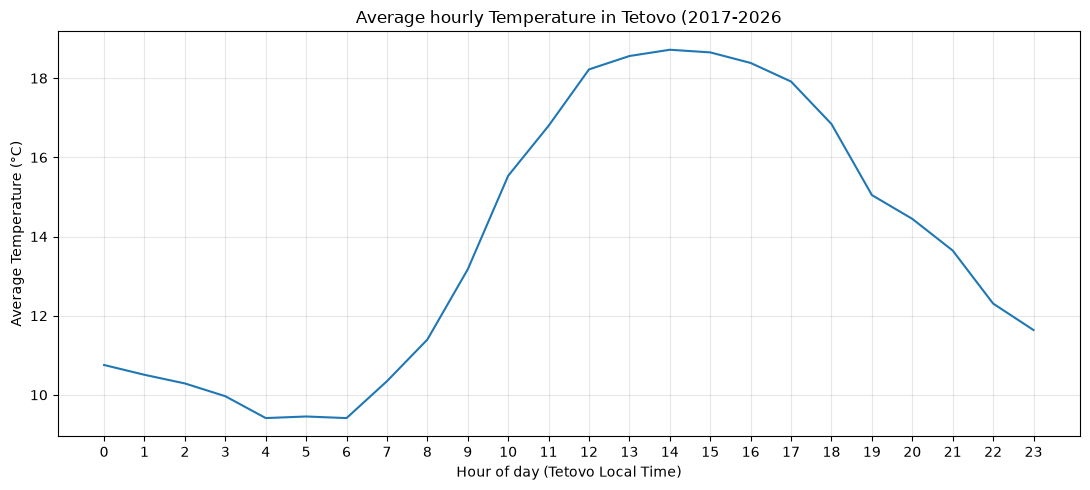

In [72]:
# Extract local hour from Tetovo timestamps 

df['hour'] = df['timestamp_local'].dt.hour

# Calculate mean temperature for each hour 

hourly_temp = df.groupby("hour")['temperature_c'].mean()

plt.figure(figsize=(11,5))

sns.lineplot(
    x = hourly_temp.index, 
    y= hourly_temp.values,
    markers='o'
)

plt.title("Average hourly Temperature in Tetovo (2017-2026")
plt.xlabel("Hour of day (Tetovo Local Time)")
plt.ylabel("Average Temperature (°C)")
plt.xticks(range(0,24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Key Observations — Hourly Temperature Patterns

Looking at how the temperature changes hour-by-hour throughout the day in Tetovo (2017–2026), we can see a very clear daily rhythm.

**Main Findings:**
* **Early Morning Lows:** The coolest part of the day usually hits between **4:00 AM and 6:00 AM**, averaging around 9.4°C.
* **Morning Warm-up:** Things start heating up fast right after **7:00 AM**.
* **Afternoon Peak:** The warmest time of the day happens around **2:00 PM (14:00)**, hitting an average high of about 18.7°C.
* **Evening Cool-down:** After the afternoon peak, temperatures steadily drop back down as evening sets in.
* **The Daily Swing:** Overall, there is a **9.3°C difference** between the coldest hour and the warmest hour of a typical day.

---

### Why This Matters for Air Pollution Prediction

Tracking this daily temperature cycle can be really helpful when studying hourly changes in air pollution. Daily weather shifts—like how the air mixes or how the atmosphere behaves above the city—can directly impact pollution levels. 

Once we merge our weather and pollution datasets, we'll check to see if pollution levels actually follow this same daily pattern.

In [73]:
# identifying the coldest and warmest average hours

coldest_hour =  hourly_temp.idxmin()
warmest_hour = hourly_temp.idxmax()

coldest_avg = hourly_temp.min()
warmest_avg = hourly_temp.max()

print(f"Coldest average hour: {coldest_hour:02d}:00")
print(f"Average temperature: {coldest_avg:.2f}°C")

print(f"\nWarmest average hour: {warmest_hour:02d}:00")
print(f"Average temperature: {warmest_avg:.2f}°C") 

print(f"\n Difference: {warmest_avg-coldest_avg:.2f}°C")

Coldest average hour: 06:00
Average temperature: 9.41°C

Warmest average hour: 14:00
Average temperature: 18.72°C

 Difference: 9.31°C


## 5. Relative Humidity Analysis

This section examines the distribution and temporal
patterns of relative humidity in Tetovo.

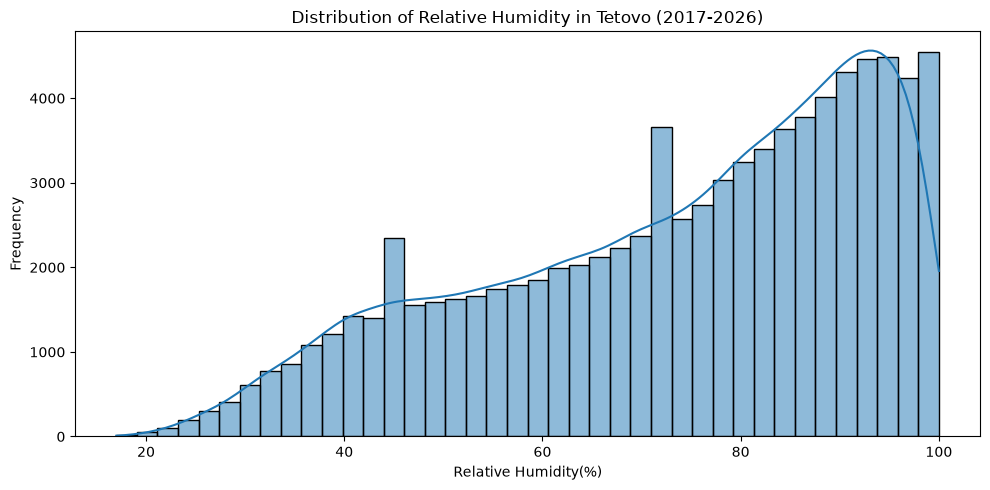

In [74]:
plt.figure(figsize=(10,5))

sns.histplot(
    data =df, 
    x='humidity_pct', 
    bins=40, 
    kde=True, 
)

plt.title("Distribution of Relative Humidity in Tetovo (2017-2026)")
plt.xlabel("Relative Humidity(%)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

### Key Observations — Relative Humidity Distribution

An analysis of hourly relative humidity level measurements in Tetovo (spanning 2017 to September 2026) reveals that atmospheric conditions in the region lean consistently toward higher moisture levels.

**Key Findings:**
* **Prevalence of High Humidity:** Moisture levels regularly cluster in the **70% to 100%** range, with a significant concentration of records exceeding 85%.
* **Negatively Skewed Distribution:** The data distribution displays a notable leftward skew, featuring a prolonged tail that drops off toward lower humidity thresholds rather than following a typical symmetrical bell curve.
* **Infrequent Arid Conditions:** Notably dry atmospheric states—specifically readings falling below 30% relative humidity—occur relatively rarely across the dataset.
* **Frequency Spikes:** Specific numerical values recur at elevated frequencies, which may point to sensor rounding, artifacts within the underlying meteorological data model, or recurring microclimate patterns.

---

### Relevance to Air Pollution Forecasting

Relative humidity serves as a critical parameter in air quality modeling, as elevated ambient moisture directly influences aerosol formation, chemical reactivity, and the physical expansion of particulate matter. Furthermore, high humidity can alter the optical properties of airborne particles, impacting sensor detection accuracy. 

Upon integrating the meteorological and air-quality datasets, we will quantitatively evaluate the non-linear interactions between humidity levels and PM2.5/PM10 concentrations across different seasonal contexts.

In [75]:
humidity = df['humidity_pct']

print(f"Mean humidity:{humidity.mean():.2f}%")
print(f"Median humidity:{humidity.median():.2f}%")
print(f"Minimum humidity:{humidity.min()}%")
print(f"Skewness:{humidity.skew():.2f}")

print(f"Hours with humidity >= 80% {(humidity>=80).mean()*100:.2f}%")

print("\nMost frequent humidity values:")
print(humidity.value_counts().head(10))

Mean humidity:73.38%
Median humidity:78.00%
Minimum humidity:17%
Skewness:-0.60
Hours with humidity >= 80% 46.95%

Most frequent humidity values:
humidity_pct
94    2280
93    2238
92    2226
95    2202
91    2157
90    2153
96    2131
97    2107
89    2027
88    1984
Name: count, dtype: int64


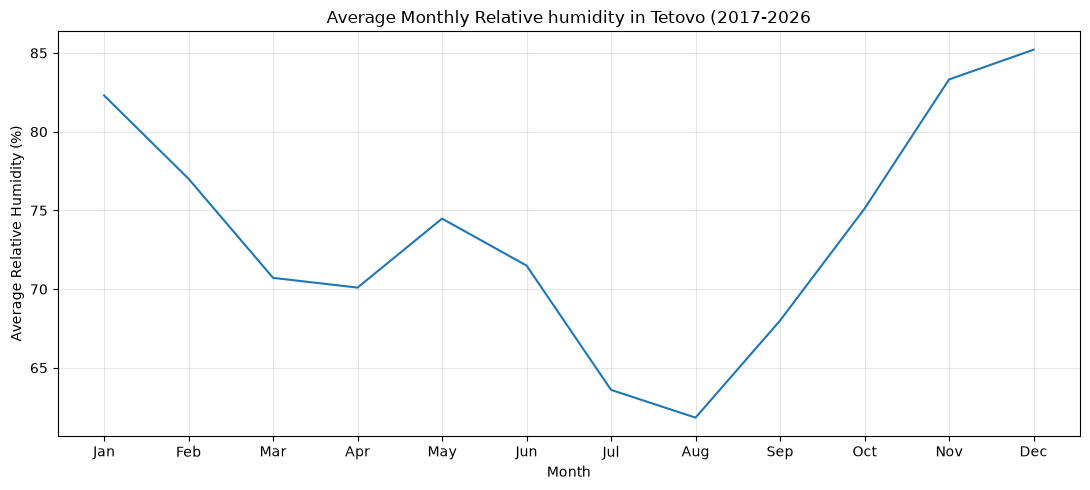

In [76]:
#Average hhumidity by month
monthly_humidity = df.groupby("month")["humidity_pct"].mean()

plt.figure(figsize=(11,5))
sns.lineplot(
    x= monthly_humidity.index,
    y=monthly_humidity.values,
    markers="o"
)

plt.xticks(
    range(1,13), 
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)

plt.title("Average Monthly Relative humidity in Tetovo (2017-2026")
plt.xlabel("Month")
plt.ylabel("Average Relative Humidity (%)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Key Observations — Monthly Relative Humidity

An evaluation of monthly relative humidity patterns in Tetovo from January 2017 to September 2026 demonstrates a distinct seasonal moisture cycle.

**Key Findings:**
* **Winter Elevation:** Atmospheric moisture peaks during the winter season. December exhibits the highest average humidity at approximately 85%, closely tracked by November and January.
* **Spring Fluctuation:** Humidity levels experience a gradual decline from February through April, interrupted by a temporary upward adjustment in May.
* **Summer Suppression:** July and August record the lowest average moisture levels, with August bottoming out near 62%.
* **Autumn Accumulation:** Relative humidity increases progressively from September through December as regional cooling takes effect.
* **Amplitude:** The variance between peak and trough monthly averages spans approximately 23 percentage points.

---

### Relevance to Air Pollution Forecasting

Seasonal shifts in relative humidity play a vital role in modulating aerosol dynamics and altering particulate matter readings. The elevated humidity characteristic of colder months indicates that moisture should be analyzed concurrently with thermal and seasonal indicators when evaluating PM2.5 and PM10 metrics. 

Nevertheless, these descriptive trends alone do not confirm a direct correlation between high atmospheric moisture and increased pollution concentrations in Tetovo. This relationship will be rigorously evaluated and tested upon merging the meteorological and air-quality datasets.

In [77]:
# Identify the months with highest and lowest hhumidity 

highest_month = monthly_humidity.idxmax()
lowest_month = monthly_humidity.idxmin() 

month_names = [
     "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

print(f"Highest humedity: {month_names[highest_month-1]} {monthly_humidity.max():.2f}%") 

print(f"Lowest humidity: {month_names[lowest_month-1]} {monthly_humidity.min():.2f}%")

print(f"Difference: {monthly_humidity.max() - monthly_humidity.min():.2f} percentage points")

Highest humedity: December 85.21%
Lowest humidity: August 61.83%
Difference: 23.38 percentage points


### Hourly Relative Humidity Patterns
The nexxt analysis investigates how relative humidity varies throughout the day in Tetovo.


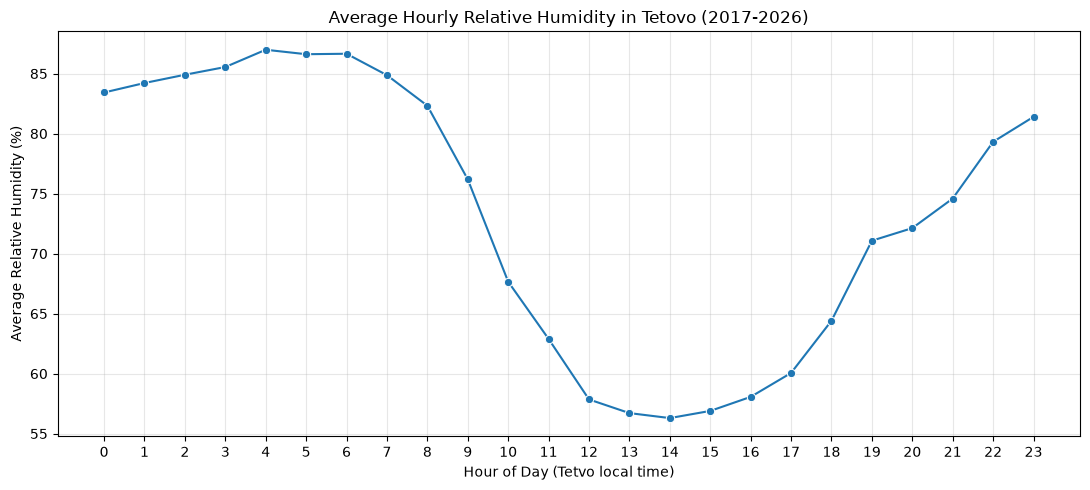

In [78]:
# Average relative humidity by local hour 
hourly_humidity = df.groupby("hour")['humidity_pct'].mean()

plt.figure(figsize=(11,5))

sns.lineplot(
    x= hourly_humidity.index, 
    y = hourly_humidity.values,
    marker = 'o'
)

plt.title("Average Hourly Relative Humidity in Tetovo (2017-2026)")
plt.xlabel("Hour of Day (Tetvo local time)")
plt.ylabel("Average Relative Humidity (%)")

plt.xticks(range(0,24))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Key Observations — Hourly Relative Humidity

An analysis of hourly relative humidity patterns in Tetovo across the study period (2017–September 2026) exhibits a well-defined and consistent diurnal cycle.

**Key Findings:**
* **Early Morning Peak:** Mean relative humidity reaches a maximum of approximately 87% between 04:00 and 06:00.
* **Morning Reduction:** Moisture levels decrease sharply following the 08:00 hour as solar heating takes effect.
* **Afternoon Trough:** The daily minimum relative humidity, averaging approximately 56%, occurs concurrently with peak thermal hours around 14:00.
* **Evening Recovery:** Relative humidity rises steadily throughout the evening and overnight hours as temperatures cool.
* **Diurnal Amplitude:** The absolute variation between peak and trough hourly averages spans approximately 31 percentage points.

---

### Thermal Comparison

The diurnal moisture cycle displays a distinct **inverse relationship** with the hourly temperature profile. Peak humidity conditions align precisely with the coolest early-morning hours, whereas minimum moisture levels correspond directly with the warmest afternoon hours.

---



In [79]:
# Hourly humidity statistics

max_hour = hourly_humidity.idxmax()
min_hour = hourly_humidity.idxmin()

print(f"Highest humidity hour: {max_hour:02d}:00")
print(f"Highest average humidity: {hourly_humidity.max():.2f}%")

print(f"\nLowest humidity hour: {min_hour:02d}:00")
print(f"Lowest average humidity: {hourly_humidity.min():.2f}%")

difference = hourly_humidity.max() - hourly_humidity.min()

print(f"\nDaily variation: {difference:.2f} percentage points")

Highest humidity hour: 04:00
Highest average humidity: 86.99%

Lowest humidity hour: 14:00
Lowest average humidity: 56.30%

Daily variation: 30.69 percentage points


pearson correlation: -0.596


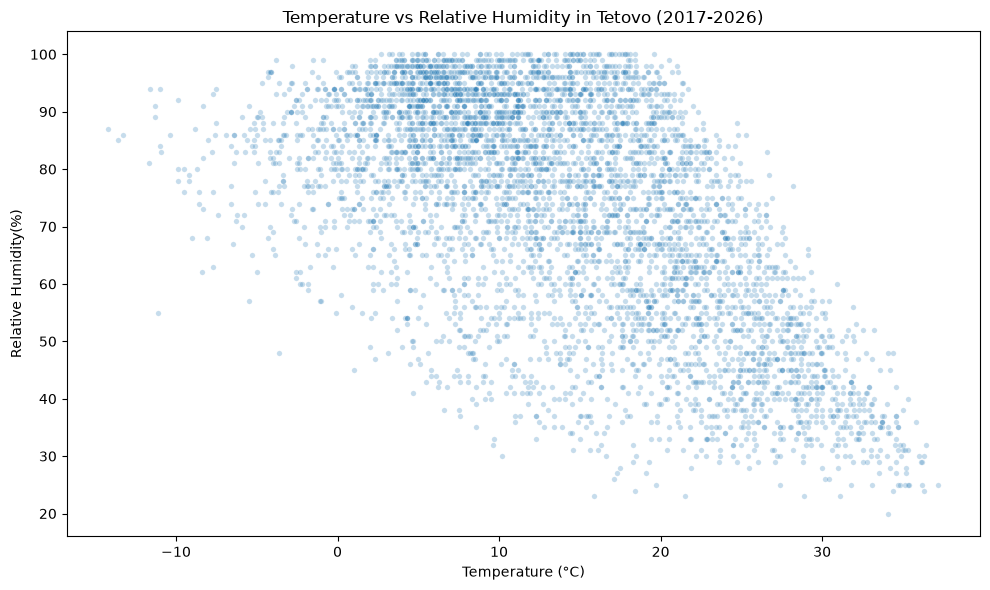

In [80]:
# Temperature and humidity correlation 
correlation = df["temperature_c"].corr(df["humidity_pct"])

print(f"pearson correlation: {correlation:.3f}")

# Sample observation for a readable scatter plot 
sample = df[['temperature_c', "humidity_pct"]].sample(
    n=5000, 
    random_state= 42,
)

plt.figure(figsize=(10,6))

sns.scatterplot(
    data= sample, 
    x= "temperature_c", 
    y="humidity_pct",
    alpha =0.25,
    s =15
)
plt.title("Temperature vs Relative Humidity in Tetovo (2017-2026)")
plt.xlabel("Temperature (°C)")
plt.ylabel("Relative Humidity(%)")

plt.tight_layout()
plt.show()

### Key Observations — Temperature and Relative Humidity Correlation

The relationship between temperature and relative humidity was examined using the Pearson correlation coefficient and a scatter plot derived from 5,000 randomly sampled hourly observations from the Tetovo ERA5 weather dataset (2017–September 2026).

**Key Findings:**
* **Moderate Negative Correlation:** The Pearson correlation coefficient is $r = -0.596$, indicating a moderate negative linear relationship between ambient temperature and relative humidity.
* **Inverse Association:** Higher temperatures are generally associated with lower relative humidity levels.
* **Dispersion and Variability:** The scatter plot displays substantial dispersion, demonstrating that temperature alone does not entirely account for variations in relative humidity.
* **Alignment with Diurnal Cycles:** This statistical relationship directly reflects the previously noted daily patterns, where thermal peaks in the afternoon coincide with daily humidity minimums.

---

### Relevance to Air Pollution Forecasting

Both temperature and relative humidity serve as valuable meteorological predictors for air quality modeling. Their moderate negative correlation implies that while these variables share underlying physical information, they are non-interchangeable and capture distinct atmospheric behaviors. 

Subsequent analysis will evaluate their individual and combined predictive contributions once the meteorological and air pollution datasets are fully integrated.

---


## 6. Seasonal Temperature and Humidity Analysis

This section examines seasonal changes in temperature
and relative humidity in Tetovo.

The objective is to identify meteorological patterns
that may help explain seasonal variations in PM2.5
concentrations during the next phase of the project.

In [81]:
# Use complete calendar years for seasonal analysis
seasonal_df = df[
    (df["timestamp_local"].dt.year >= 2017) &
    (df["timestamp_local"].dt.year <= 2025)
].copy()

# Extract month
seasonal_df["month"] = seasonal_df["timestamp_local"].dt.month

# Assign meteorological seasons
season_map = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Autumn", 10: "Autumn", 11: "Autumn"
}

seasonal_df["season"] = seasonal_df["month"].map(season_map)

season_order = ["Winter", "Spring", "Summer", "Autumn"]

# Calculate seasonal averages
seasonal_stats = (
    seasonal_df.groupby("season")[
        ["temperature_c", "humidity_pct"]
    ]
    .mean()
    .reindex(season_order)
)

display(seasonal_stats.round(2))

,temperature_c,humidity_pct
season,,
Winter,4.21,81.19
Spring,12.48,71.93
Summer,23.34,66.00
Autumn,14.43,75.58


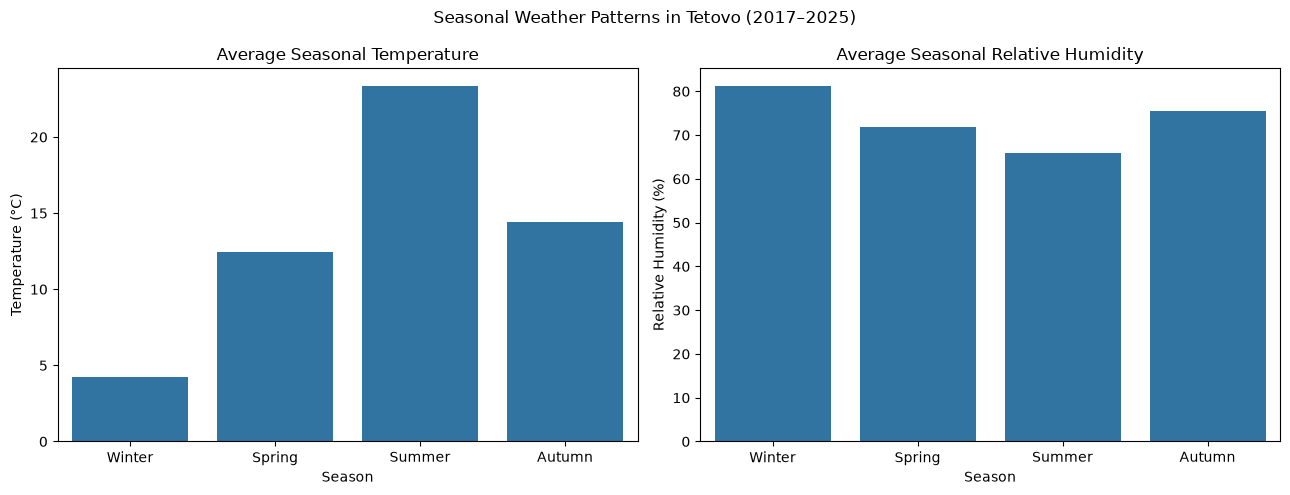

In [82]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Seasonal temperature
sns.barplot(
    x=seasonal_stats.index,
    y=seasonal_stats["temperature_c"],
    ax=axes[0]
)

axes[0].set_title("Average Seasonal Temperature")
axes[0].set_xlabel("Season")
axes[0].set_ylabel("Temperature (°C)")

# Seasonal humidity
sns.barplot(
    x=seasonal_stats.index,
    y=seasonal_stats["humidity_pct"],
    ax=axes[1]
)

axes[1].set_title("Average Seasonal Relative Humidity")
axes[1].set_xlabel("Season")
axes[1].set_ylabel("Relative Humidity (%)")

plt.suptitle(
    "Seasonal Weather Patterns in Tetovo (2017–2025)"
)

plt.tight_layout()
plt.show()

### Key Observations — Seasonal Temperature and Humidity

The seasonal analysis of Tetovo's historical ERA5 weather data (2017–2025) demonstrates distinct thermodynamic differences across the four meteorological seasons.

**Temperature Findings:**
* **Winter Baseline:** Winter represents the coldest season, maintaining a mean temperature of approximately 4.2°C.
* **Summer Peak:** Summer records the highest thermal averages, peaking at approximately 23.3°C.
* **Transition Seasons:** Spring and autumn occupy intermediate thermal ranges, with autumn exhibiting slightly warmer average conditions than spring.

**Relative Humidity Findings:**
* **Winter Saturation:** Winter exhibits the highest seasonal relative humidity, averaging approximately 81%.
* **Summer Desiccation:** Summer registers the lowest average relative humidity, dropping to approximately 66%.
* **Transition Levels:** Spring and intermediate autumn months display moderate relative humidity levels bridging the seasonal extremes.

---

### Overall Interpretation

These seasonal averages highlight a clear macro-level **inverse relationship** between ambient temperature and relative humidity. Warmer seasons consistently feature lower relative humidity levels, whereas colder seasons correspond with elevated atmospheric moisture. This seasonal dynamic aligns directly with the moderate negative Pearson correlation ($r = -0.596$) established in prior analyses.

---

### Relevance to Air Pollution Forecasting

These pronounced seasonal shifts provide critical temporal context for investigating cyclical patterns in particulate matter concentrations. Temperature, relative humidity, and seasonal categorical indicators emerge as robust candidate features for future predictive modeling. Their ultimate utility will be rigorously evaluated following the integration of the meteorological and air-quality datasets.

*Note on Causality:* This descriptive analysis demonstrates temporal patterns rather than causation; it does not prove that seasonal phase shifts or moisture levels independently drive variations in $\text{PM}_{2.5}$ concentrations.

## 7. Conclusion and Limitations

### 7.1 Conclusion

This Exploratory Data Analysis (EDA) examined historical meteorological conditions in Tetovo, North Macedonia, using hourly ERA5 weather data obtained through the Open-Meteo Historical Weather API, covering January 2017 to September 2026.

The analysis focused on **temperature and relative humidity**, the two meteorological variables that will also be measured by our planned IoT monitoring system.

The dataset contains **85,440 hourly observations**, with no missing values or duplicate timestamps identified during the initial data quality assessment.

### Key Findings

**1. Temperature Patterns**

- Temperature exhibits clear seasonal and daily variations.
- Summer is the warmest season, with an average temperature of approximately 23.3°C, while winter is the coldest at approximately 4.2°C.
- Average hourly temperatures are lowest during the early morning and highest around 14:00 local time.
- The temperature distribution reflects substantial variation between colder and warmer conditions throughout the year.

**2. Relative Humidity Patterns**

- Relative humidity is generally higher during winter and lower during summer.
- Winter records an average relative humidity of approximately 81%, compared with approximately 66% during summer.
- The highest average hourly humidity occurs during the early morning, while the lowest occurs around 14:00.
- The humidity distribution is concentrated toward higher values, with relatively dry conditions occurring less frequently.

**3. Temperature–Humidity Relationship**

- Pearson correlation analysis identified a moderate negative relationship between temperature and relative humidity (**r = −0.596**).
- Higher temperatures are generally associated with lower relative humidity.
- The hourly and seasonal visualizations support this inverse pattern.
- The scatter plot also reveals considerable variability, suggesting that temperature alone does not fully explain relative humidity.

### 7.2 Limitations

Despite providing useful insights, this analysis has several limitations.

**1. Historical Reanalysis Data**

The dataset was obtained from the Open-Meteo Historical Weather API using ERA5 reanalysis data. These values represent historical atmospheric estimates rather than direct observations from our own IoT sensors.

Consequently, differences may exist between the historical dataset and future measurements collected by the physical monitoring system.

**2. Incomplete Final Year**

The dataset covers January 2017 through September 2026. Therefore, 2026 is not a complete calendar year.

The seasonal comparison was restricted to 2017–2025 to avoid including the incomplete final calendar year.

**3. Limited Meteorological Scope**

Although the original dataset contains additional weather variables, this phase focused specifically on temperature and relative humidity to align with the planned IoT hardware.

Wind speed, wind direction, atmospheric pressure, and precipitation were not investigated in detail.

These variables may be considered in future model comparisons using external weather data.

**4. Correlation Does Not Imply Causation**

The negative temperature–humidity correlation describes a statistical association and does not establish a causal relationship.

Seasonal cycles, time of day, and other atmospheric conditions may contribute to the observed patterns.

**5. Air Pollution Relationships Not Yet Evaluated**

This analysis examined meteorological variables independently of air pollution measurements.

No conclusions can yet be drawn about the relationship between temperature, humidity, and PM2.5 concentrations in Tetovo.

These relationships will be investigated once the weather and pollution datasets have been integrated.

**6. Historical Data and Forecasting Constraints**

Historical weather conditions are useful for understanding past patterns, but actual future weather observations are not available when making real-time predictions.

Future forecasting experiments must use information that would have been available at the time of prediction to avoid data leakage.

### 7.3 Next Steps

The findings from this EDA will support subsequent phases of the collaborative IoT air pollution forecasting project.

The next stages include:

1. Integrating historical temperature and humidity records with the Tetovo PM2.5 pollution dataset.
2. Resolving and documenting timestamp alignment between the two data sources.
3. Investigating relationships between meteorological conditions and PM2.5 concentrations.
4. Developing and evaluating baseline machine-learning forecasting models.
5. Incorporating measurements from the planned IoT sensors to evaluate real-world system performance.

### 7.4 Final Remarks

This analysis establishes an initial understanding of temperature and relative humidity patterns in Tetovo and provides a foundation for further environmental data analysis.

By identifying temporal variations, seasonal differences, and relationships between weather variables, this phase contributes to the preparation of historical data for the broader IoT-based air pollution forecasting project.

The findings will be revisited after integration with the PM2.5 dataset and evaluated for their usefulness in predicting air pollution concentrations.